# Heart Disease Prediction using Machine Learning

**Course:** Fundamentals of Machine Learning – Programming Assignment
**Group members:** *MS26923406*, *MS26923338*
**Dataset:** UCI Heart Disease Data
**Dataset source:** https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data

**Problem:** Predict whether a patient has heart disease from clinical measurements (binary classification, supervised learning).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import pandas as pd
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42
sns.set_style("whitegrid")

## Load the dataset
The loader tries the `ucimlrepo` package first, then the raw UCI file

In [2]:
COLS = ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

def load_data():
    try:
        df = pd.read_csv("heart_disease_uci.csv")

        # Assign column names only if needed
        if len(df.columns) == len(COLS):
            df.columns = COLS
        else:
            raise ValueError("Unexpected number of columns")

        print("Dataset loaded successfully")
        return df

    except Exception as e:
        print(f"Cannot load the dataset: {e}")
        raise

df = load_data()

# Convert only numeric columns
num_cols = ['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak']

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)


Dataset loaded successfully
Dataset shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object


## Prepare the data

The original target (`target`, also called `num` in the source dataset) uses values from 0 to 4. We convert it to a binary target: **0 = no heart disease** and **1 = heart disease present**.


In [3]:
# Remove rows with missing target values
df = df.dropna(subset=["num"]).copy()

# Convert num into a binary target:
# 0 = No disease, greater than 0 = Disease
df["target"] = (pd.to_numeric(df["num"], errors="coerce") > 0).astype(int)

print("Dataset rows and columns:", df.shape)

print("\nMissing values by column:")
missing_values = df.isna().sum()
print(
    missing_values[missing_values > 0]
    if missing_values.any()
    else "No missing values found."
)

print("\nClass counts:")
print(
    df["target"].value_counts()
    .sort_index()
    .rename(index={0: "No disease", 1: "Disease"})
)

print("\nClass proportions:")
print(
    df["target"].value_counts(normalize=True)
    .sort_index()
    .round(3)
    .rename(index={0: "No disease", 1: "Disease"})
)

print("\nDescriptive statistics:")
display(df.describe().T.round(2))

Dataset rows and columns: (920, 17)

Missing values by column:
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64

Class counts:
target
No disease    411
Disease       509
Name: count, dtype: int64

Class proportions:
target
No disease    0.447
Disease       0.553
Name: proportion, dtype: float64

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
id,920.0,460.50,265.73,1.0,230.75,460.5,690.25,920.0
age,920.0,53.51,9.42,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.13,19.07,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.13,110.78,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.55,25.93,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.88,1.09,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.68,0.94,0.0,0.00,0.0,1.00,3.0
num,920.0,1.00,1.14,0.0,0.00,1.0,2.00,4.0
target,920.0,0.55,0.50,0.0,0.00,1.0,1.00,1.0


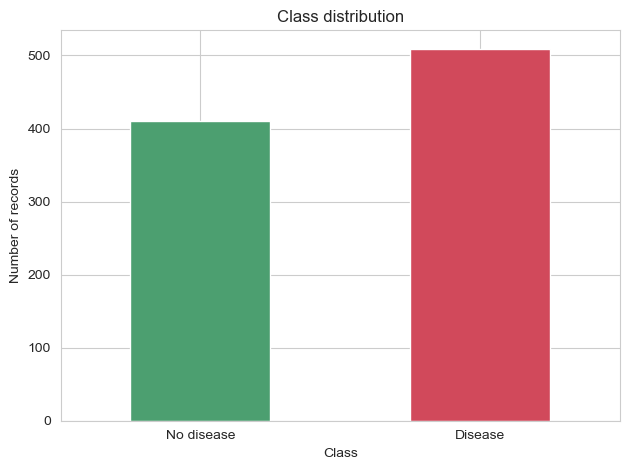

In [4]:
df["target"].value_counts().sort_index().plot(
    kind="bar", color=["#4C9F70", "#D1495B"]
)

plt.xticks([0, 1], ["No disease", "Disease"], rotation=0)
plt.title("Class distribution")
plt.ylabel("Number of records")
plt.xlabel("Class")

plt.tight_layout()
plt.show()

### Train/test split and preprocessing pipeline

- We keep 20% of the data for final testing and use stratification to preserve the class proportions.
- Numeric columns are imputed with the median and scaled.
- Categorical columns are imputed with the most frequent value and one-hot encoded.

In [5]:
X = df.drop(columns="target")
y = df["target"]
# num_cols = ["age","trestbps","chol","thalach","oldpeak","ca"]
# cat_cols = ["sex","cp","fbs","restecg","exang","slope","thal"]
num_cols = ['id','age','trestbps','chol','thalch','oldpeak']
cat_cols = ['sex','dataset','cp','fbs','restecg','exang','slope','ca','thal','num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training records: 736
Testing records: 184


## Algorithm 1: Random Forest

In [6]:
rf_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
])

rf_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [None, 4, 8],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features": ["sqrt", "log2"],
}

rf_search = GridSearchCV(
    rf_pipe, rf_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best training CV F1-score:", round(rf_search.best_score_, 4))

Best Random Forest parameters: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Best training CV F1-score: 1.0


## Algorithm 2: Support Vector Machine

In [7]:
svm_pipe = Pipeline([
    ("prep", preprocess), 
    ("clf", SVC(probability=True, random_state=RANDOM_STATE))
])

svm_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.1],
    "clf__kernel": ["rbf", "linear"],
}

svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="f1", n_jobs=-1)
svm_search.fit(X_train, y_train)

print("Best params:", svm_search.best_params_)
print("Best CV F1 :", round(svm_search.best_score_, 4))

svm_best = svm_search.best_estimator_

Best params: {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
Best CV F1 : 1.0


## Final evaluation on the held-out test set

The following metrics are calculated from predictions on the test set, which was not used to tune the models. Because this is a medical classification example, recall is important to discuss alongside the other metrics.

In [8]:
def evaluate_model(name, model):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

models = [("Random Forest", rf_best), ("SVM", svm_best)]
results = pd.DataFrame([evaluate_model(name, model) for name, model in models]).set_index("Model")
display(results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,1.0,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0,1.0


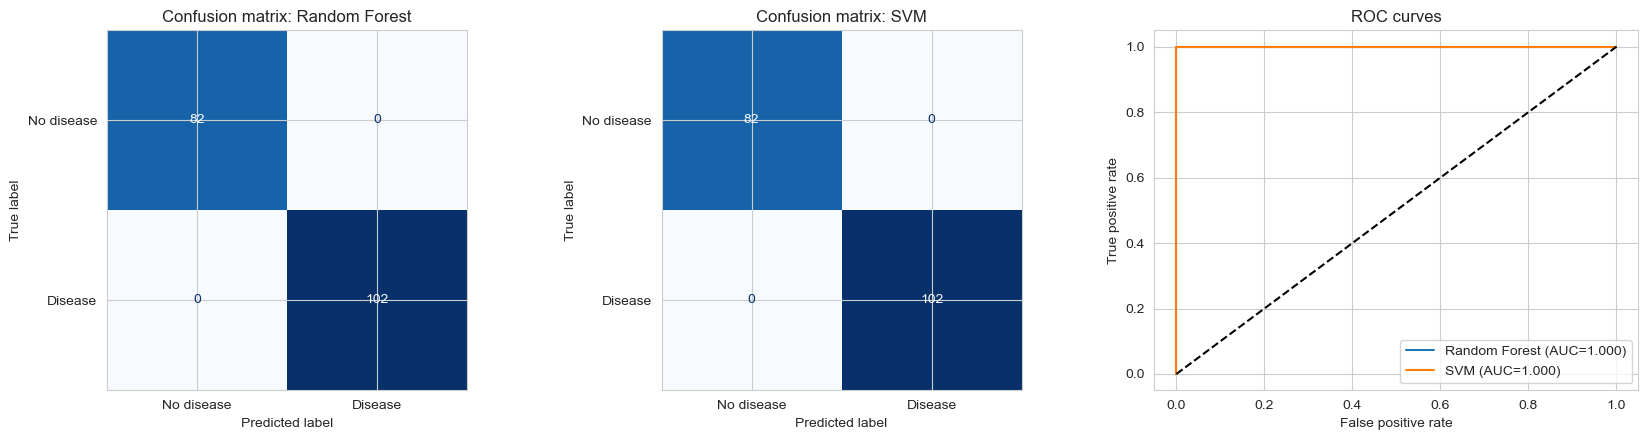

--- Random Forest ---
              precision    recall  f1-score   support

  No disease       1.00      1.00      1.00        82
     Disease       1.00      1.00      1.00       102

    accuracy                           1.00       184
   macro avg       1.00      1.00      1.00       184
weighted avg       1.00      1.00      1.00       184

--- SVM ---
              precision    recall  f1-score   support

  No disease       1.00      1.00      1.00        82
     Disease       1.00      1.00      1.00       102

    accuracy                           1.00       184
   macro avg       1.00      1.00      1.00       184
weighted avg       1.00      1.00      1.00       184



In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, (name, m) in zip(axes[:2], [("Random Forest", rf_best), ("SVM", svm_best)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {name}")
    
for name, m in [("Random Forest", rf_best), ("SVM", svm_best)]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:,1]):.3f})")
    
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curves"); axes[2].legend()
plt.tight_layout(); plt.show()

for name, m in [("Random Forest", rf_best), ("SVM", svm_best)]:
    print(f"--- {name} ---")
    print(classification_report(y_test, m.predict(X_test), target_names=["No disease", "Disease"]))

### Cross-validation results used during tuning

The table below reports the mean and standard deviation of the **best F1-score across the five training folds** for each grid search. These scores helped select the hyperparameters; they are not a separate unbiased test of the final model. Use the held-out test-set table above for the final model comparison.

In [10]:
cv_rows = []
for name, search in [("Random Forest", rf_search), ("SVM", svm_search)]:
    best_index = search.best_index_
    cv_rows.append({
        "Model": name,
        "Best mean CV F1-score": search.cv_results_["mean_test_score"][best_index],
        "CV F1 standard deviation": search.cv_results_["std_test_score"][best_index],
    })

cv_summary = pd.DataFrame(cv_rows).set_index("Model")
display(cv_summary.round(4))

,Best mean CV F1-score,CV F1 standard deviation
Model,,
Random Forest,1.0,0.0
SVM,1.0,0.0


## 7. Feature importance

Random Forest provides an estimate of feature importance. These scores describe how much the fitted forest used each transformed feature; they do not prove that a feature causes heart disease. One-hot encoding means a single original categorical variable may appear as several features.

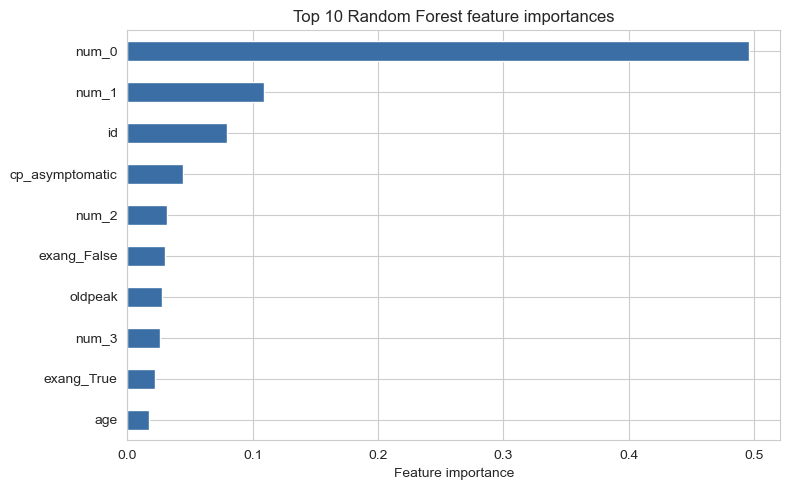

In [11]:
onehot_names = (
    rf_best.named_steps["prep"]
    .named_transformers_["cat"]
    .named_steps["oh"]
    .get_feature_names_out(cat_cols)
)

feature_names = num_cols + list(onehot_names)

importances = pd.Series(
    rf_best.named_steps["clf"].feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

importances.sort_values().plot(
    kind="barh", figsize=(8, 5), color="#3A6EA5"
)

plt.xlabel("Feature importance")
plt.title("Top 10 Random Forest feature importances")
plt.tight_layout()
plt.show()